In [4]:
# 1. Install dependencies (run once if needed)
# In a fresh Jupyter environment, uncomment the next line:
# %pip install pandas numpy matplotlib seaborn scikit-learn statsmodels torch

In [5]:
# 2. Import libraries and set reproducibility
import os, random, warnings, copy
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", DEVICE)

PyTorch device: cpu


In [6]:
# 3. Load dataset
# Keep the CSV in the same folder as this notebook, or update DATA_PATH.
DATA_PATH = "Renewable_Climate_Solar_Wind_Updated.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\\nColumns:", df.columns.tolist())
display(df.head())
display(df.info())

Dataset shape: (58297, 12)
\nColumns: ['date', 'state_name', 'wind_energy', 'solar_energy', 'total_renewable_energy', 'T2M', 'RH2M', 'PRECIPITATION', 'WS10M', 'WS50M', 'ALLSKY_SFC_SW_DWN', 'CLOUD_AMT']


,date,state_name,wind_energy,solar_energy,total_renewable_energy,T2M,RH2M,PRECIPITATION,WS10M,WS50M,ALLSKY_SFC_SW_DWN,CLOUD_AMT
0,28-05-2020,andhra pradesh,29.95,9.23,39.18,36.68,48.06,0.01,4.90,6.03,6.9533,59.66
1,29-05-2020,andhra pradesh,32.23,9.83,42.06,36.86,43.16,0.03,6.27,7.72,6.9182,67.12
2,30-05-2020,andhra pradesh,17.53,7.85,25.38,35.84,45.73,0.08,4.48,5.42,5.8620,92.13
3,01-06-2020,andhra pradesh,5.58,8.69,14.27,32.64,57.49,0.86,3.25,3.99,5.5037,83.45
4,02-06-2020,andhra pradesh,13.14,11.40,24.54,31.79,61.82,7.58,3.10,3.89,6.2861,79.56


<class 'pandas.DataFrame'>
RangeIndex: 58297 entries, 0 to 58296
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    58297 non-null  str    
 1   state_name              58297 non-null  str    
 2   wind_energy             58249 non-null  float64
 3   solar_energy            58267 non-null  float64
 4   total_renewable_energy  58249 non-null  float64
 5   T2M                     58297 non-null  float64
 6   RH2M                    58297 non-null  float64
 7   PRECIPITATION           58297 non-null  float64
 8   WS10M                   58297 non-null  float64
 9   WS50M                   58297 non-null  float64
 10  ALLSKY_SFC_SW_DWN       58297 non-null  float64
 11  CLOUD_AMT               58297 non-null  float64
dtypes: float64(10), str(2)
memory usage: 6.4 MB


None

In [7]:
# 4. Data audit and cleaning
required_columns = [
    "date", "state_name", "wind_energy", "solar_energy",
    "T2M", "RH2M", "PRECIPITATION", "WS10M", "WS50M",
    "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from CSV: {missing_columns}")

df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")
df["state_name"] = df["state_name"].astype(str).str.strip().str.lower()

numeric_cols = [c for c in required_columns if c not in ["date", "state_name"]]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Rows:", len(df))
print("States/UTs:", df["state_name"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("\\nMissing values before cleaning:")
display(df.isna().sum().to_frame("missing_count"))

# Two or more records for the same state/date are combined by their mean.
# This is appropriate for duplicate daily observations, rather than counting them twice.
df = (df.dropna(subset=["date", "state_name"])
        .groupby(["state_name", "date"], as_index=False)[numeric_cols]
        .mean()
        .sort_values(["state_name", "date"])
        .reset_index(drop=True))

# Drop rows where either target is unavailable; do not invent target values.
df = df.dropna(subset=["wind_energy", "solar_energy"]).copy()

# Fill any remaining missing weather input values within each state's time series.
weather_cols = ["T2M", "RH2M", "PRECIPITATION", "WS10M", "WS50M",
                "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"]
df[weather_cols] = (df.groupby("state_name")[weather_cols]
                      .transform(lambda s: s.interpolate(limit_direction="both")))
df = df.dropna(subset=weather_cols).reset_index(drop=True)

print("Cleaned shape:", df.shape)
print("States/UTs:", df["state_name"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Duplicate state-date rows:", int(df.duplicated(["state_name", "date"]).sum()))

Rows: 58297
States/UTs: 33
Date range: 2020-05-28 00:00:00 to 2025-04-27 00:00:00
\nMissing values before cleaning:


,missing_count
date,0
state_name,0
wind_energy,48
solar_energy,30
total_renewable_energy,48
T2M,0
RH2M,0
PRECIPITATION,0
WS10M,0
WS50M,0


Cleaned shape: (58247, 11)
States/UTs: 33
Date range: 2020-05-28 00:00:00 to 2025-04-27 00:00:00
Remaining missing values: 0
Duplicate state-date rows: 0


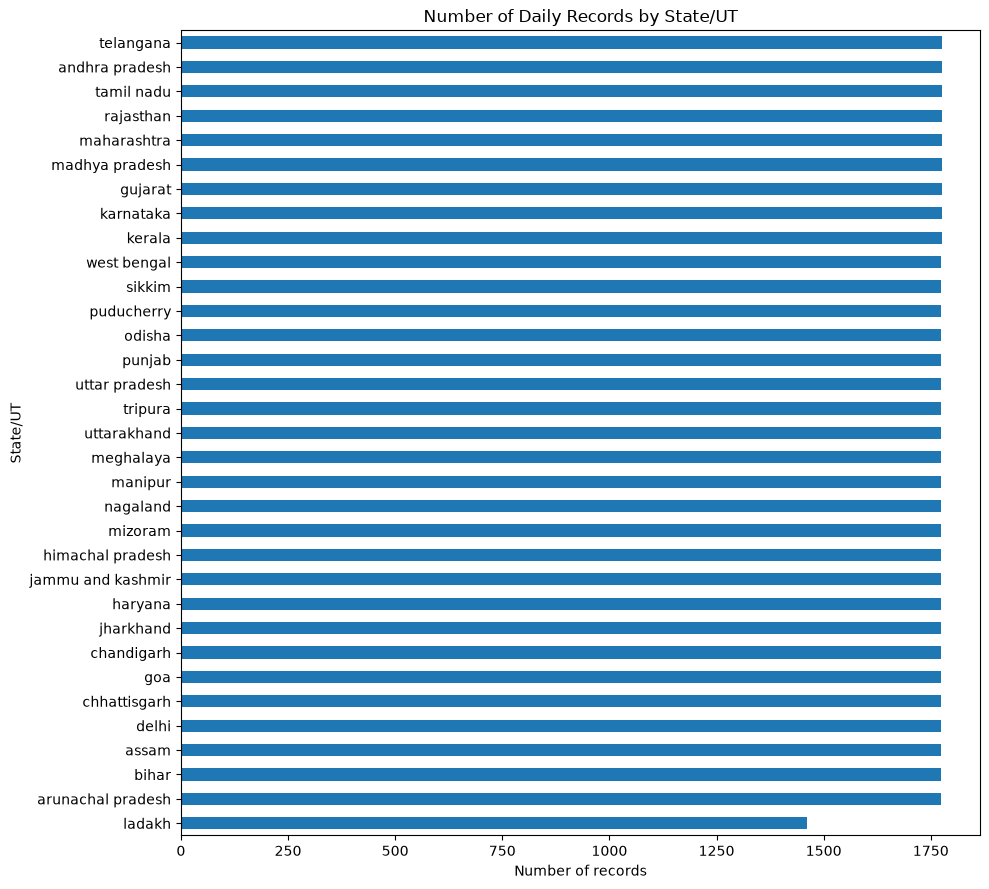

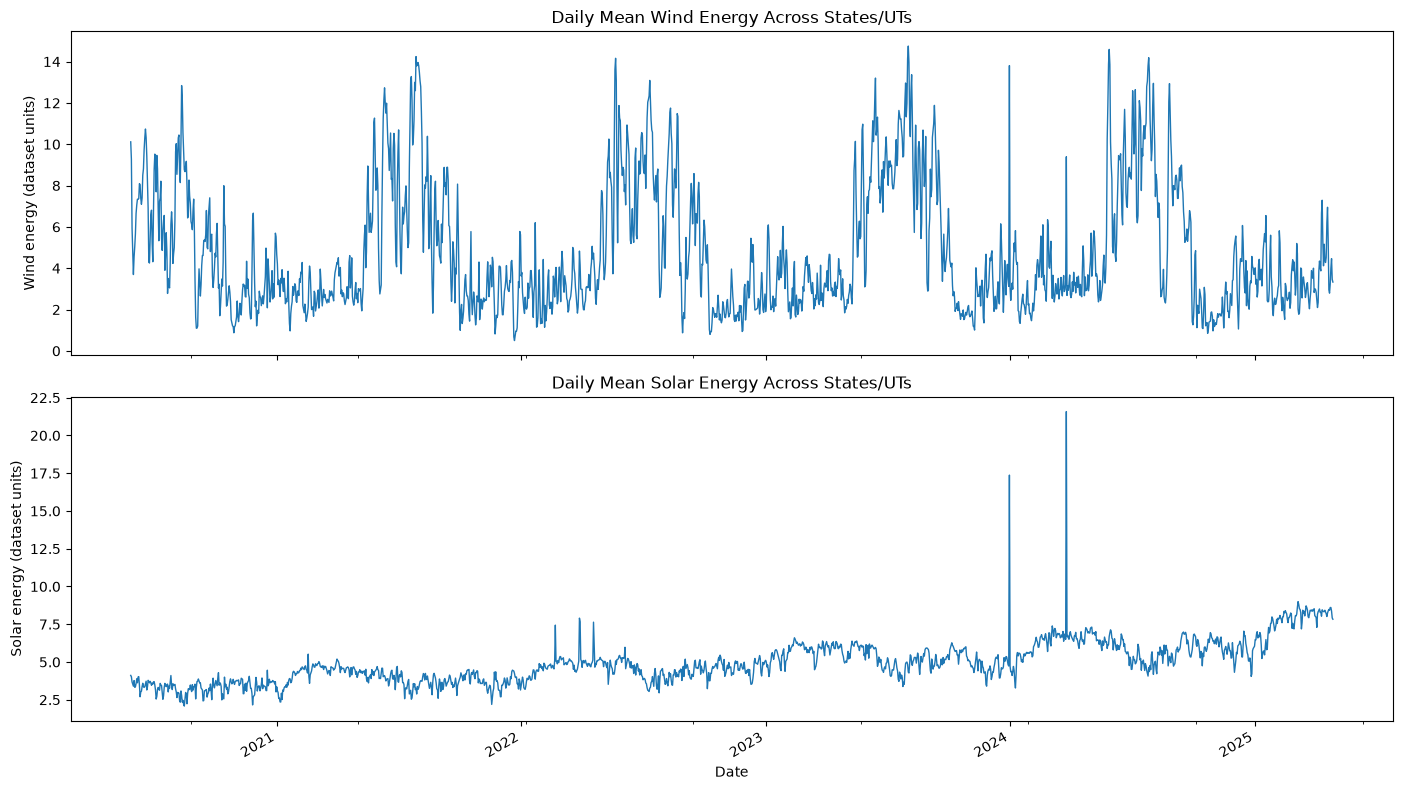

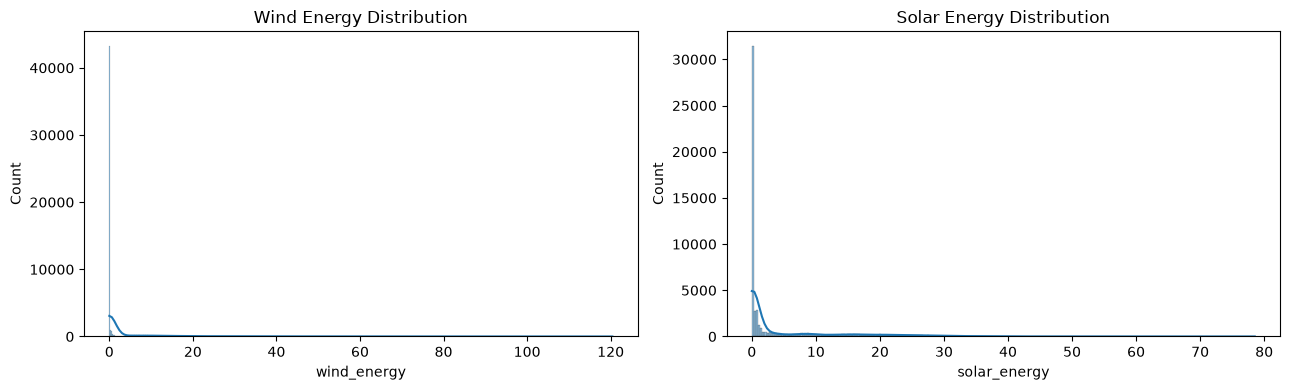

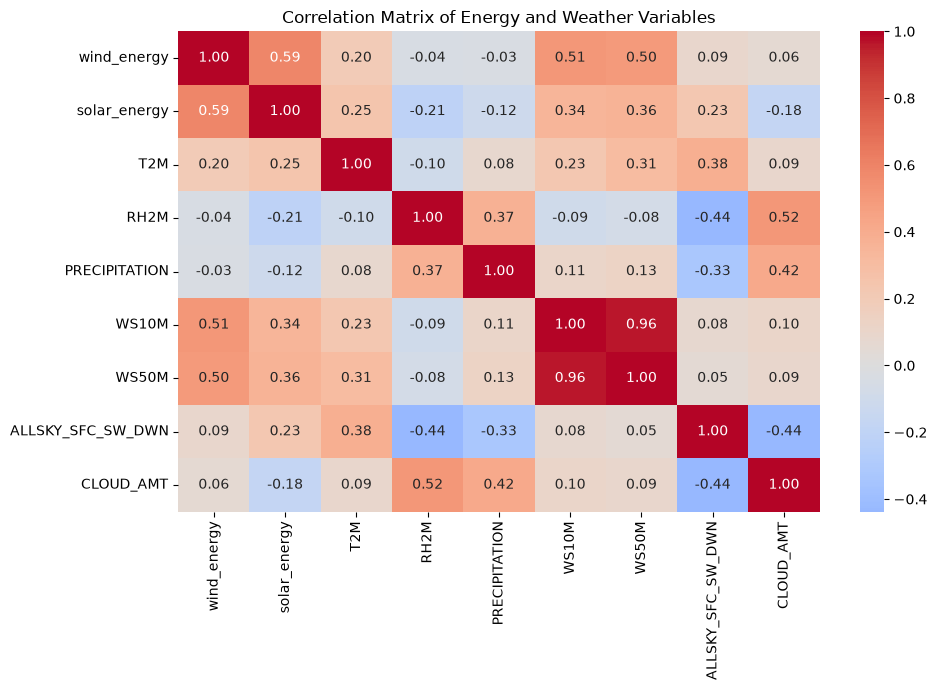

In [8]:
# 5. Exploratory data analysis (EDA)
# Number of records by state/UT
state_counts = df.groupby("state_name").size().sort_values()
plt.figure(figsize=(10, 9))
state_counts.plot(kind="barh")
plt.title("Number of Daily Records by State/UT")
plt.xlabel("Number of records")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()

# Overall daily mean target trends (mean across available states)
daily_mean = df.groupby("date")[["wind_energy", "solar_energy"]].mean()
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
daily_mean["wind_energy"].plot(ax=axes[0], linewidth=1)
axes[0].set_title("Daily Mean Wind Energy Across States/UTs")
axes[0].set_ylabel("Wind energy (dataset units)")
daily_mean["solar_energy"].plot(ax=axes[1], linewidth=1)
axes[1].set_title("Daily Mean Solar Energy Across States/UTs")
axes[1].set_ylabel("Solar energy (dataset units)")
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

# Distribution and correlation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["wind_energy"], kde=True, ax=axes[0])
axes[0].set_title("Wind Energy Distribution")
sns.histplot(df["solar_energy"], kde=True, ax=axes[1])
axes[1].set_title("Solar Energy Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Matrix of Energy and Weather Variables")
plt.tight_layout()
plt.show()

## 2. Methodology

### 2.1 Exponential Smoothing (SES)

SES assigns larger weights to recent observations. Its one-step-ahead equation is:

\[
\hat{y}_{t+1}=\alpha y_t+(1-\alpha)\hat{y}_t,\quad 0<\alpha<1
\]

The SES model is fitted separately for each state/UT and each target. It is a univariate benchmark and does not use weather variables.

### 2.2 LSTM

LSTM uses input, forget, and output gates to learn long- and short-term temporal dependencies. Here, a 14-day sequence is used to forecast the next day's energy.

### 2.3 CNN–LSTM

A 1-D convolution extracts local patterns from the multivariate sequence. The resulting feature sequence is passed to an LSTM, which learns temporal dependencies.

### 2.4 Smooth CNN–LSTM

An exponential moving average (EMA) smooths each input feature sequence before it enters the CNN–LSTM. This is the notebook's explicit implementation of the paper-inspired smoothing hybrid. The smoothing factor is fixed at 0.30 for reproducibility; it can be tuned using validation data in further experiments.

### 2.5 Evaluation metrics

\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
\]

\[
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
\]

\[
RMSE=\sqrt{MSE},\qquad
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
\]

Lower MAE, MSE, and RMSE are better. Higher R² is generally better. R² can be negative when a model performs worse than predicting the test-set mean.

In [9]:
# 6. Feature engineering
# Cyclical calendar features preserve the circular nature of day-of-year and day-of-week.
df["day_of_year"] = df["date"].dt.dayofyear
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

df["doy_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

# One-hot encoding allows one global model to learn across states/UTs.
state_dummies = pd.get_dummies(df["state_name"], prefix="state", dtype=float)
df = pd.concat([df, state_dummies], axis=1)

# Past target values are included as inputs; the target is shifted by one day
# when creating windows, so no future target values enter the input sequence.
feature_cols = weather_cols + ["doy_sin", "doy_cos", "dow_sin", "dow_cos",
                               "wind_energy", "solar_energy"] + state_dummies.columns.tolist()
target_cols = ["wind_energy", "solar_energy"]

print("Number of input features:", len(feature_cols))
print("Input features:", feature_cols)

Number of input features: 46
Input features: ['T2M', 'RH2M', 'PRECIPITATION', 'WS10M', 'WS50M', 'ALLSKY_SFC_SW_DWN', 'CLOUD_AMT', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'wind_energy', 'solar_energy', 'state_andhra pradesh', 'state_arunachal pradesh', 'state_assam', 'state_bihar', 'state_chandigarh', 'state_chhattisgarh', 'state_delhi', 'state_goa', 'state_gujarat', 'state_haryana', 'state_himachal pradesh', 'state_jammu and kashmir', 'state_jharkhand', 'state_karnataka', 'state_kerala', 'state_ladakh', 'state_madhya pradesh', 'state_maharashtra', 'state_manipur', 'state_meghalaya', 'state_mizoram', 'state_nagaland', 'state_odisha', 'state_puducherry', 'state_punjab', 'state_rajasthan', 'state_sikkim', 'state_tamil nadu', 'state_telangana', 'state_tripura', 'state_uttar pradesh', 'state_uttarakhand', 'state_west bengal']


In [10]:
# 7. Chronological split and sequence construction
# For each state, the earliest 80% of dates are training data and the latest 20% are test data.
# Scalers are fitted only on training rows to prevent information leakage.
LOOKBACK = 14
TRAIN_FRACTION = 0.80

train_row_mask = pd.Series(False, index=df.index)
test_row_mask = pd.Series(False, index=df.index)

for state, idx in df.groupby("state_name").groups.items():
    state_idx = list(idx)
    state_idx = sorted(state_idx, key=lambda i: df.loc[i, "date"])
    cut = int(len(state_idx) * TRAIN_FRACTION)
    train_row_mask.loc[state_idx[:cut]] = True
    test_row_mask.loc[state_idx[cut:]] = True

x_scaler = StandardScaler()
y_scaler = StandardScaler()
x_scaler.fit(df.loc[train_row_mask, feature_cols])
y_scaler.fit(df.loc[train_row_mask, target_cols])

X_scaled = x_scaler.transform(df[feature_cols]).astype(np.float32)
Y_scaled = y_scaler.transform(df[target_cols]).astype(np.float32)

X_train, Y_train, X_test, Y_test = [], [], [], []
meta_train, meta_test = [], []

for state, group in df.groupby("state_name", sort=False):
    idx = group.sort_values("date").index.to_numpy()
    for pos in range(LOOKBACK, len(idx)):
        window_idx = idx[pos-LOOKBACK:pos]
        target_idx = idx[pos]
        x_window = X_scaled[window_idx]
        y_value = Y_scaled[target_idx]
        metadata = (state, df.loc[target_idx, "date"])

        if train_row_mask.loc[target_idx]:
            X_train.append(x_window); Y_train.append(y_value); meta_train.append(metadata)
        elif test_row_mask.loc[target_idx]:
            X_test.append(x_window); Y_test.append(y_value); meta_test.append(metadata)

X_train = np.asarray(X_train, dtype=np.float32)
Y_train = np.asarray(Y_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)
Y_test = np.asarray(Y_test, dtype=np.float32)

meta_train = pd.DataFrame(meta_train, columns=["state_name", "date"])
meta_test = pd.DataFrame(meta_test, columns=["state_name", "date"])

print("Training sequences:", X_train.shape, Y_train.shape)
print("Testing sequences:", X_test.shape, Y_test.shape)
print("Input shape = (samples, lookback days, features)")
print("Output shape = (samples, 2 targets: wind_energy and solar_energy)")

Training sequences: (46123, 14, 46) (46123, 2)
Testing sequences: (11662, 14, 46) (11662, 2)
Input shape = (samples, lookback days, features)
Output shape = (samples, 2 targets: wind_energy and solar_energy)


In [11]:
# 8. Create PyTorch data loaders
BATCH_SIZE = 256
train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(Y_train))
test_ds = TensorDataset(torch.tensor(X_test), torch.tensor(Y_test))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

N_FEATURES = X_train.shape[2]
N_TARGETS = Y_train.shape[1]
print("Features:", N_FEATURES, "| Targets:", N_TARGETS, "| Device:", DEVICE)

Features: 46 | Targets: 2 | Device: cpu


In [23]:
# 9. Define LSTM, CNN-LSTM and Smooth CNN-LSTM architectures
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden=64, n_targets=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden,
                            num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden, n_targets)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


class CNNLSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden=64, n_targets=2, smooth_alpha=None):
        super().__init__()
        self.smooth_alpha = smooth_alpha
        self.conv = nn.Conv1d(in_channels=n_features, out_channels=64,
                              kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)
        self.lstm = nn.LSTM(input_size=64, hidden_size=hidden,
                            num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden, n_targets)

    def forward(self, x):
        # Smooth CNN-LSTM: causal exponential smoothing of the input sequence.
        if self.smooth_alpha is not None:
            alpha = self.smooth_alpha
            smoothed = []
            prev = x[:, 0, :]
            smoothed.append(prev)
            for t in range(1, x.shape[1]):
                prev = alpha * x[:, t, :] + (1 - alpha) * prev
                smoothed.append(prev)
            x = torch.stack(smoothed, dim=1)

        x = x.transpose(1, 2)      # (batch, features, time)
        x = self.relu(self.conv(x))
        x = self.pool(x)
        x = x.transpose(1, 2)      # (batch, time, channels)
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


def build_model(model_name):
    if model_name == "LSTM":
        return LSTMForecaster(N_FEATURES).to(DEVICE)
    if model_name == "CNN-LSTM":
        return CNNLSTMForecaster(N_FEATURES).to(DEVICE)
    if model_name == "Smooth CNN-LSTM":
        return CNNLSTMForecaster(N_FEATURES, smooth_alpha=0.30).to(DEVICE)
    raise ValueError(model_name)

In [24]:
# 10. Train and predict deep-learning models
def train_model(model, train_loader, epochs=18, learning_rate=0.001):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(xb)

        epoch_loss = running_loss / len(train_loader.dataset)
        history.append(epoch_loss)
        if (epoch + 1) % 3 == 0:
            print(f"Epoch {epoch+1:02d}/{epochs} - training MSE: {epoch_loss:.5f}")
    return history


def predict_model(model, X):
    model.eval()
    with torch.no_grad():
        tensor = torch.tensor(X, dtype=torch.float32).to(DEVICE)
        preds = []
        for start in range(0, len(tensor), 1024):
            preds.append(model(tensor[start:start+1024]).cpu().numpy())
    return np.vstack(preds)

deep_predictions_scaled = {}
training_histories = {}
EPOCHS = 18

for model_name in ["LSTM", "CNN-LSTM", "Smooth CNN-LSTM"]:
    print("\\nTraining:", model_name)
    model = build_model(model_name)
    history = train_model(model, train_loader, epochs=EPOCHS)
    training_histories[model_name] = history
    deep_predictions_scaled[model_name] = predict_model(model, X_test)

\nTraining: LSTM
Epoch 03/18 - training MSE: 0.07138
Epoch 06/18 - training MSE: 0.06503
Epoch 09/18 - training MSE: 0.06306
Epoch 12/18 - training MSE: 0.06160
Epoch 15/18 - training MSE: 0.05912
Epoch 18/18 - training MSE: 0.05788
\nTraining: CNN-LSTM
Epoch 03/18 - training MSE: 0.07171
Epoch 06/18 - training MSE: 0.06657
Epoch 09/18 - training MSE: 0.06276
Epoch 12/18 - training MSE: 0.06059
Epoch 15/18 - training MSE: 0.05807
Epoch 18/18 - training MSE: 0.05640
\nTraining: Smooth CNN-LSTM
Epoch 03/18 - training MSE: 0.08740
Epoch 06/18 - training MSE: 0.07263
Epoch 09/18 - training MSE: 0.06781
Epoch 12/18 - training MSE: 0.06534
Epoch 15/18 - training MSE: 0.06199
Epoch 18/18 - training MSE: 0.06086


In [25]:
# 11. Exponential Smoothing benchmark (state-wise, rolling one-step-ahead)
# At each test date, forecast one step ahead, then update the SES level with
# the newly observed actual value. This matches the rolling one-day-ahead
# evaluation protocol used by the sequence models.
ses_predictions = np.full((len(meta_test), 2), np.nan, dtype=float)

test_meta = meta_test.reset_index().rename(columns={"index": "test_position"})
for state in sorted(df["state_name"].unique()):
    state_train = df[(df["state_name"] == state) & train_row_mask].sort_values("date")
    state_test_meta = test_meta[test_meta["state_name"] == state].sort_values("date")
    if state_train.empty or state_test_meta.empty:
        continue

    state_test_actual = (df[(df["state_name"] == state) & test_row_mask]
                         .set_index("date").sort_index())

    for target_i, target in enumerate(target_cols):
        series = state_train[target].astype(float).values
        try:
            fitted = SimpleExpSmoothing(series, initialization_method="estimated").fit(optimized=True)
            alpha = float(fitted.params["smoothing_level"])
            level = float(fitted.fittedvalues.iloc[-1])
        except Exception:
            alpha = 0.30
            level = float(series[-1])

        for _, row in state_test_meta.iterrows():
            test_position = int(row["test_position"])
            forecast = level
            ses_predictions[test_position, target_i] = forecast

            # Update only after the actual observation for this date is available.
            actual = float(state_test_actual.loc[row["date"], target])
            level = alpha * actual + (1 - alpha) * level

# Convert predictions and targets back to original dataset units.
Y_test_original = y_scaler.inverse_transform(Y_test)
predictions = {"Exponential Smoothing": ses_predictions}
for name, pred_scaled in deep_predictions_scaled.items():
    predictions[name] = y_scaler.inverse_transform(pred_scaled)

print("SES prediction shape:", ses_predictions.shape)
print("NaN values in SES predictions:", np.isnan(ses_predictions).sum())

SES prediction shape: (11662, 2)
NaN values in SES predictions: 0


In [26]:
# 12. Calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    valid = np.isfinite(y_pred).all(axis=1) & np.isfinite(y_true).all(axis=1)
    rows = []
    for j, target in enumerate(target_cols):
        yt, yp = y_true[valid, j], y_pred[valid, j]
        rows.append({
            "Target": target,
            "MAE": mean_absolute_error(yt, yp),
            "MSE": mean_squared_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp)
        })
    return rows

metric_rows = []
for model_name, pred in predictions.items():
    for row in calculate_metrics(Y_test_original, pred):
        row["Algorithm"] = model_name
        metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)[["Target", "Algorithm", "MAE", "MSE", "RMSE", "R2"]]
display(metrics_df.round(4))

# Save metric table for later use in the report.
metrics_df.to_csv("forecasting_model_metrics.csv", index=False)
print("Saved: forecasting_model_metrics.csv")

,Target,Algorithm,MAE,MSE,RMSE,R2
0,wind_energy,Exponential Smoothing,1.7053,30.6330,5.5347,0.8483
1,solar_energy,Exponential Smoothing,0.6928,3.5122,1.8741,0.9731
2,wind_energy,LSTM,1.6188,18.1307,4.2580,0.9102
3,solar_energy,LSTM,0.9124,4.7529,2.1801,0.9635
4,wind_energy,CNN-LSTM,1.4862,18.4460,4.2949,0.9087
5,solar_energy,CNN-LSTM,0.8813,4.6428,2.1547,0.9644
6,wind_energy,Smooth CNN-LSTM,1.4781,18.4282,4.2928,0.9088
7,solar_energy,Smooth CNN-LSTM,0.8677,4.4437,2.1080,0.9659


Saved: forecasting_model_metrics.csv


## 3. Wind energy prediction analysis

The following figures reproduce the key comparison style used in the reference paper: actual-versus-predicted time-series plots, actual-versus-predicted scatter plots, and a metric comparison. All graphs are generated from the uploaded dataset's held-out chronological test period.

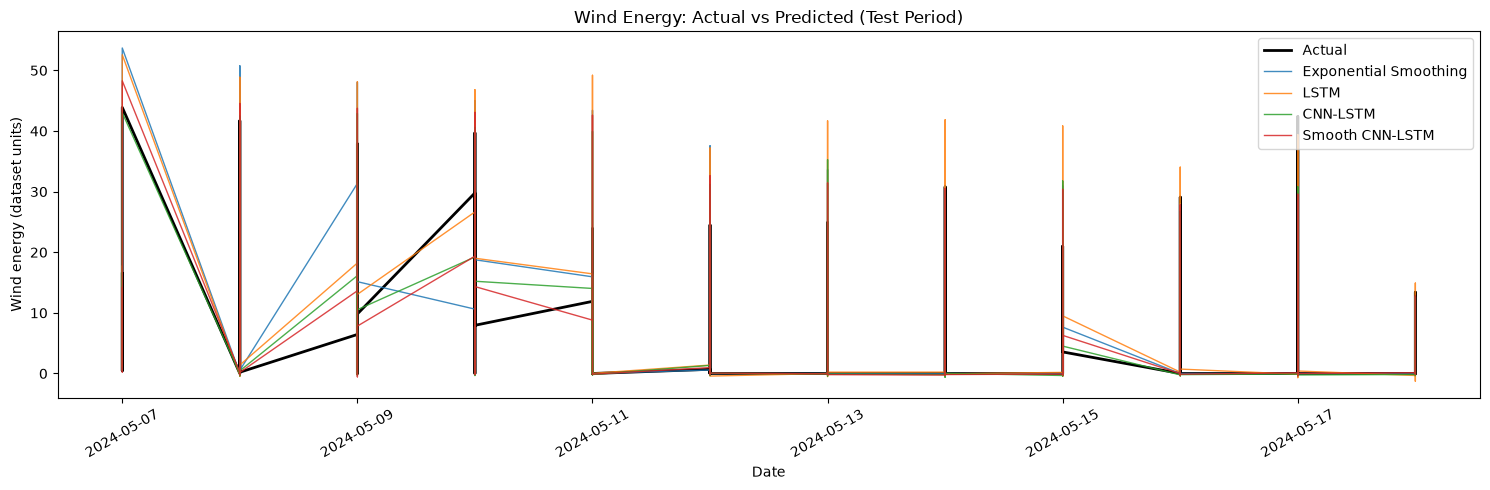

In [27]:
# 13. Wind: actual vs predicted time series
wind_i = target_cols.index("wind_energy")
plot_n = min(350, len(Y_test_original))

# Sort test predictions by date for a readable chronological plot.
wind_order = np.argsort(meta_test["date"].values)
wind_order = wind_order[:plot_n]
plt.figure(figsize=(15, 5))
plt.plot(meta_test.iloc[wind_order]["date"], Y_test_original[wind_order, wind_i],
         label="Actual", color="black", linewidth=2)
for name, pred in predictions.items():
    plt.plot(meta_test.iloc[wind_order]["date"], pred[wind_order, wind_i],
             label=name, alpha=0.85, linewidth=1)
plt.title("Wind Energy: Actual vs Predicted (Test Period)")
plt.xlabel("Date")
plt.ylabel("Wind energy (dataset units)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

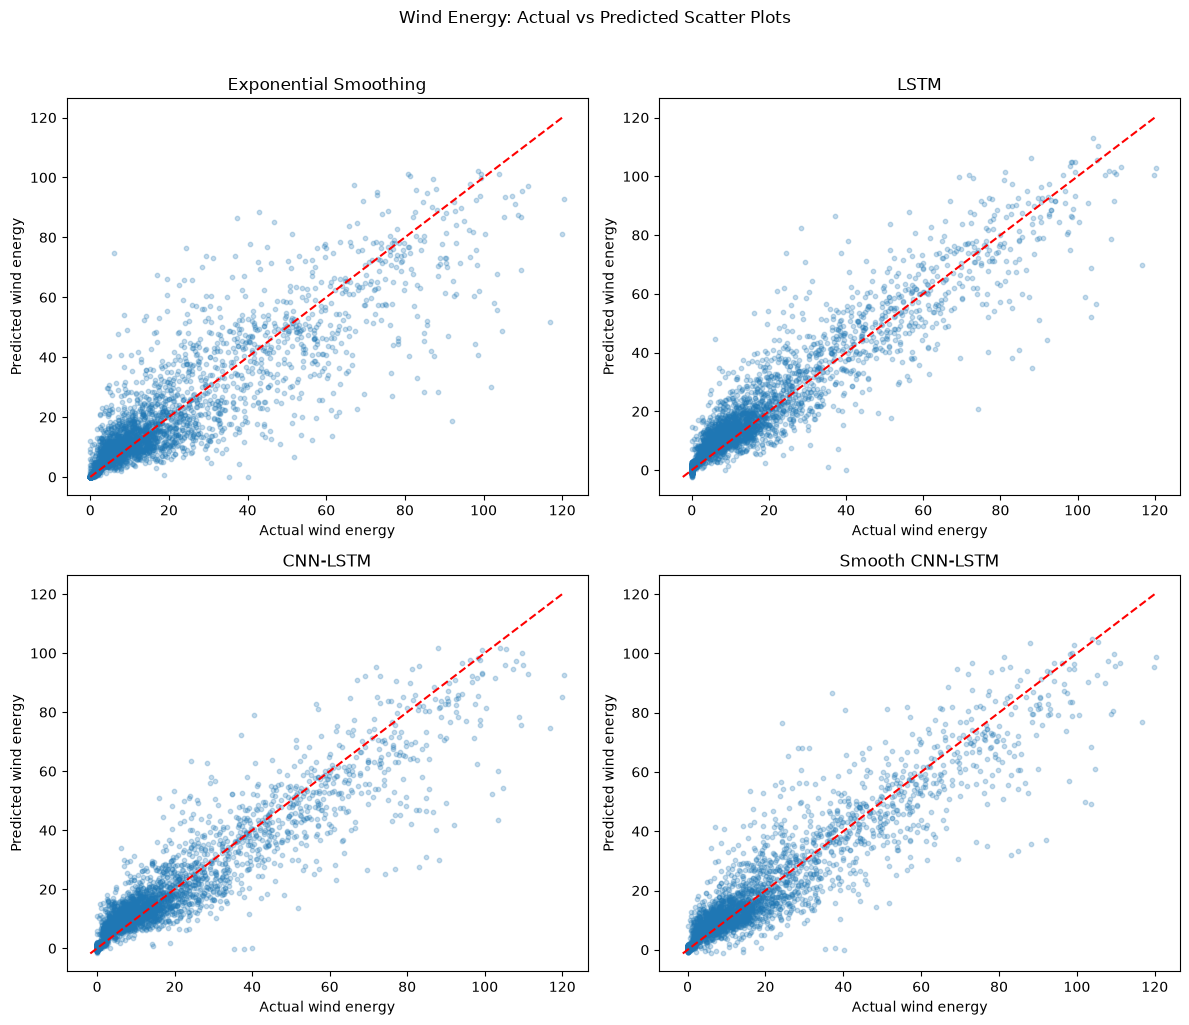

In [28]:
# 14. Wind: actual vs predicted scatter plots for each algorithm
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    valid = np.isfinite(pred[:, wind_i])
    ax.scatter(Y_test_original[valid, wind_i], pred[valid, wind_i], alpha=0.25, s=10)
    lo = min(Y_test_original[valid, wind_i].min(), pred[valid, wind_i].min())
    hi = max(Y_test_original[valid, wind_i].max(), pred[valid, wind_i].max())
    ax.plot([lo, hi], [lo, hi], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual wind energy")
    ax.set_ylabel("Predicted wind energy")
plt.suptitle("Wind Energy: Actual vs Predicted Scatter Plots", y=1.02)
plt.tight_layout()
plt.show()

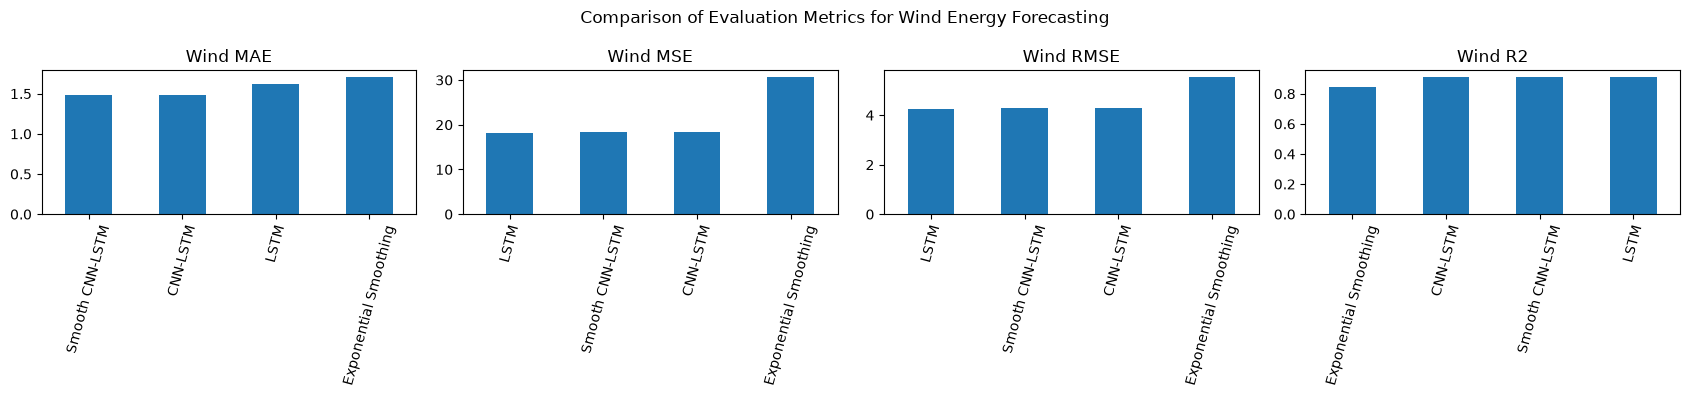

In [29]:
# 15. Wind: metric comparison
wind_metrics = metrics_df[metrics_df["Target"] == "wind_energy"].set_index("Algorithm")
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "R2"]):
    wind_metrics[metric].sort_values().plot(kind="bar", ax=ax)
    ax.set_title(f"Wind {metric}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=75)
plt.suptitle("Comparison of Evaluation Metrics for Wind Energy Forecasting")
plt.tight_layout()
plt.show()

## 4. Solar energy prediction analysis

The same trained models predict `solar_energy`. Solar results are evaluated independently from wind results using the same chronological test period and the same four metrics.

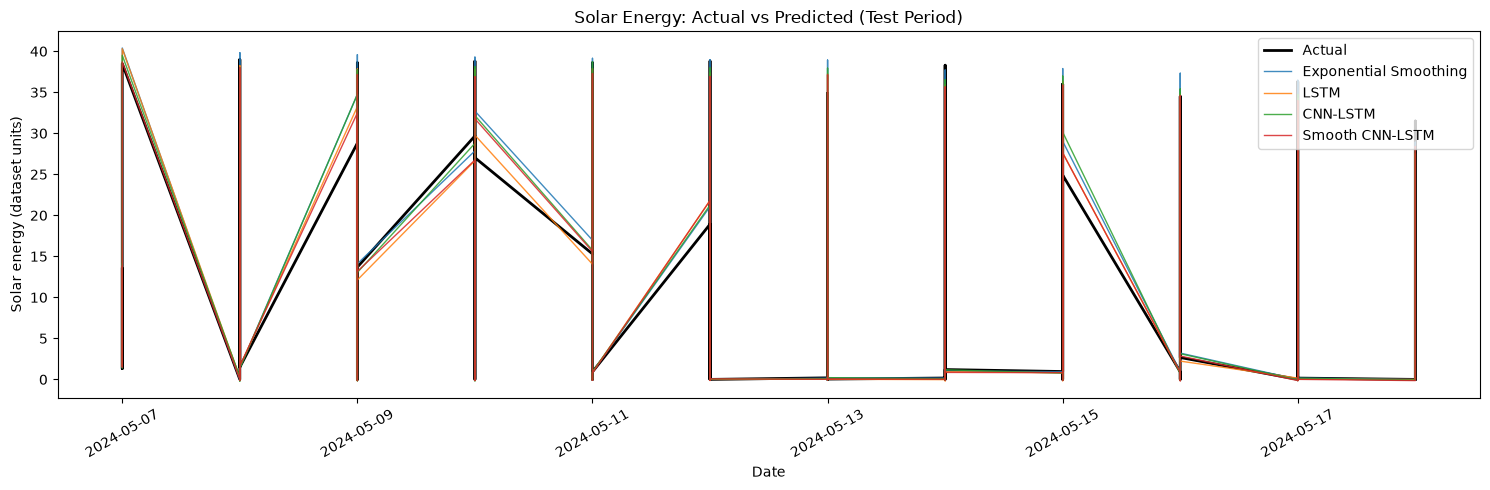

In [30]:
# 16. Solar: actual vs predicted time series
solar_i = target_cols.index("solar_energy")
solar_order = np.argsort(meta_test["date"].values)
solar_order = solar_order[:plot_n]
plt.figure(figsize=(15, 5))
plt.plot(meta_test.iloc[solar_order]["date"], Y_test_original[solar_order, solar_i],
         label="Actual", color="black", linewidth=2)
for name, pred in predictions.items():
    plt.plot(meta_test.iloc[solar_order]["date"], pred[solar_order, solar_i],
             label=name, alpha=0.85, linewidth=1)
plt.title("Solar Energy: Actual vs Predicted (Test Period)")
plt.xlabel("Date")
plt.ylabel("Solar energy (dataset units)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

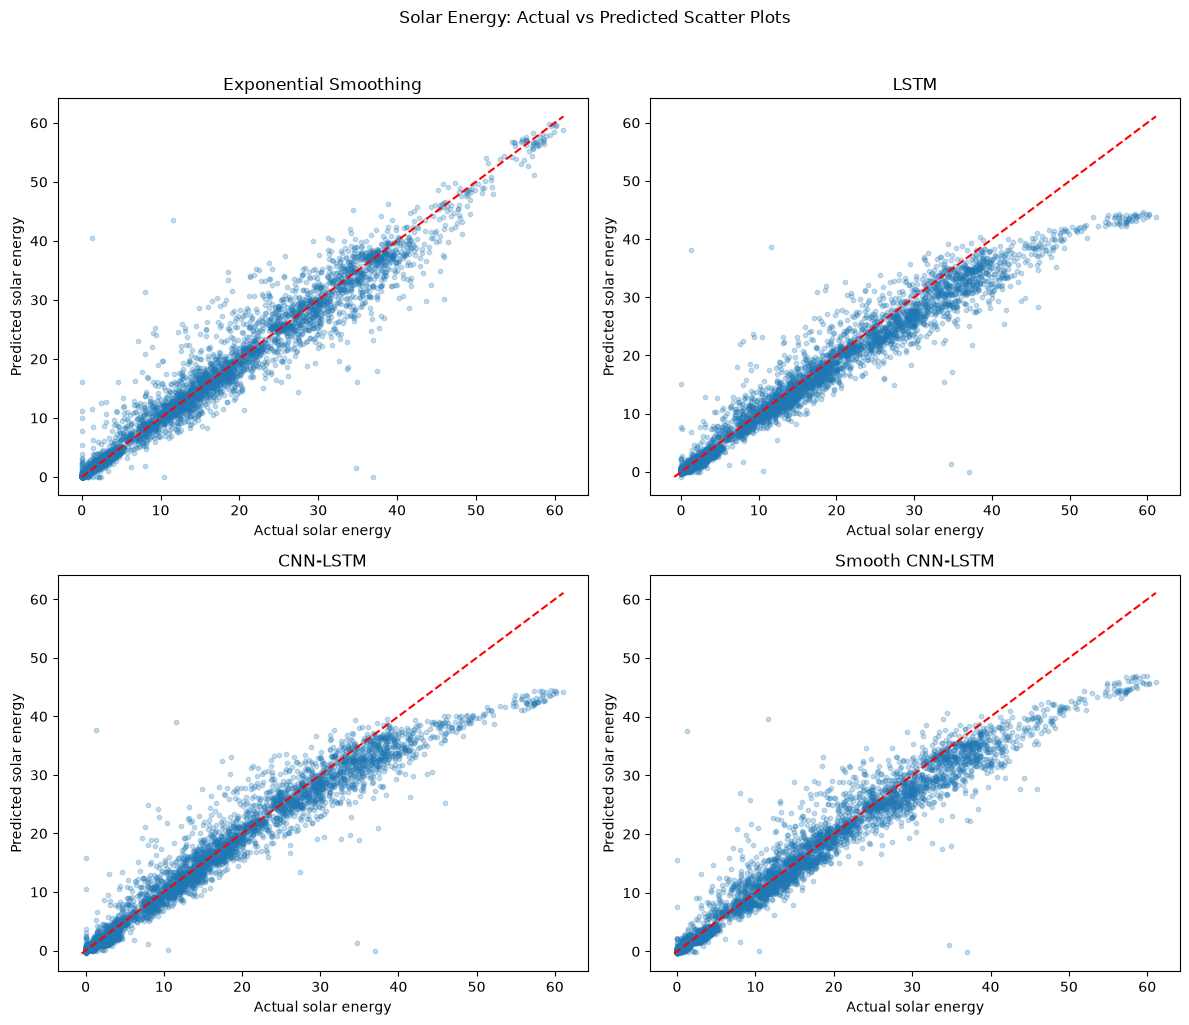

In [31]:
# 17. Solar: actual vs predicted scatter plots for each algorithm
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    valid = np.isfinite(pred[:, solar_i])
    ax.scatter(Y_test_original[valid, solar_i], pred[valid, solar_i], alpha=0.25, s=10)
    lo = min(Y_test_original[valid, solar_i].min(), pred[valid, solar_i].min())
    hi = max(Y_test_original[valid, solar_i].max(), pred[valid, solar_i].max())
    ax.plot([lo, hi], [lo, hi], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual solar energy")
    ax.set_ylabel("Predicted solar energy")
plt.suptitle("Solar Energy: Actual vs Predicted Scatter Plots", y=1.02)
plt.tight_layout()
plt.show()

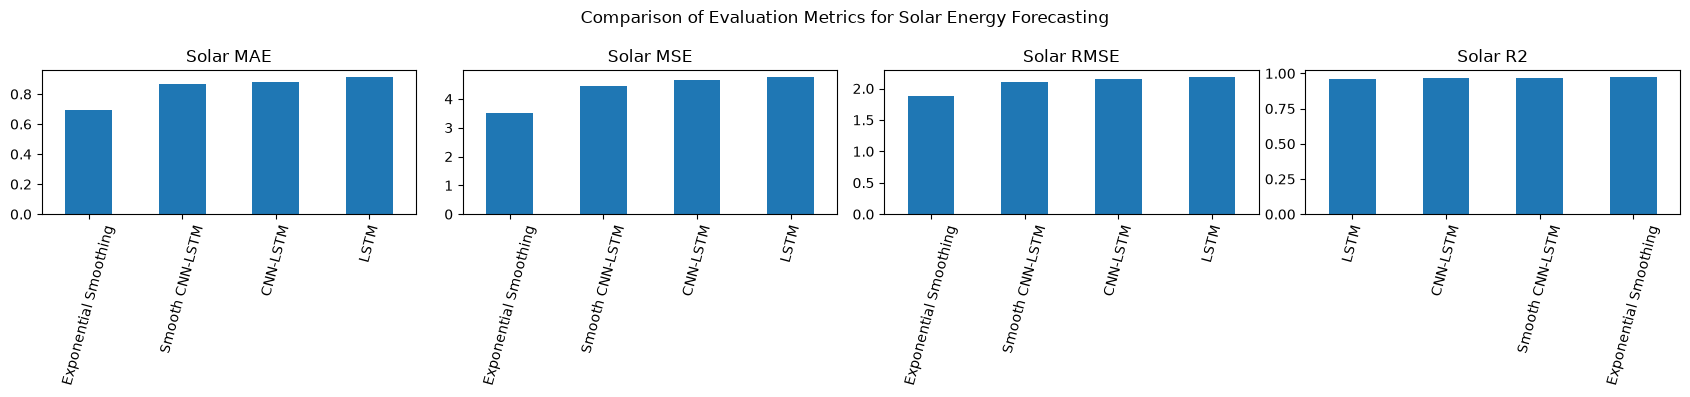

In [32]:
# 18. Solar: metric comparison
solar_metrics = metrics_df[metrics_df["Target"] == "solar_energy"].set_index("Algorithm")
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "R2"]):
    solar_metrics[metric].sort_values().plot(kind="bar", ax=ax)
    ax.set_title(f"Solar {metric}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=75)
plt.suptitle("Comparison of Evaluation Metrics for Solar Energy Forecasting")
plt.tight_layout()
plt.show()

In [33]:
# 19. Combined model comparison table and best-model identification
summary = metrics_df.pivot(index="Algorithm", columns="Target", values=["MAE", "MSE", "RMSE", "R2"])
display(summary.round(4))

best_rows = []
for target in target_cols:
    sub = metrics_df[metrics_df["Target"] == target]
    best_error = sub.loc[sub["RMSE"].idxmin()]
    best_r2 = sub.loc[sub["R2"].idxmax()]
    best_rows.append({
        "Target": target,
        "Lowest RMSE model": best_error["Algorithm"],
        "Lowest RMSE": best_error["RMSE"],
        "Highest R2 model": best_r2["Algorithm"],
        "Highest R2": best_r2["R2"]
    })
best_models_df = pd.DataFrame(best_rows)
display(best_models_df.round(4))

summary.to_csv("forecasting_summary_table.csv")
best_models_df.to_csv("best_model_summary.csv", index=False)
print("Saved: forecasting_summary_table.csv and best_model_summary.csv")

MAE                      MSE              \
Target                solar_energy wind_energy solar_energy wind_energy   
Algorithm                                                                 
CNN-LSTM                    0.8813      1.4862       4.6428     18.4460   
Exponential Smoothing       0.6928      1.7053       3.5122     30.6330   
LSTM                        0.9124      1.6188       4.7529     18.1307   
Smooth CNN-LSTM             0.8677      1.4781       4.4437     18.4282   

                              RMSE                       R2              
Target                solar_energy wind_energy solar_energy wind_energy  
Algorithm                                                                
CNN-LSTM                    2.1547      4.2949       0.9644      0.9087  
Exponential Smoothing       1.8741      5.5347       0.9731      0.8483  
LSTM                        2.1801      4.2580       0.9635      0.9102  
Smooth CNN-LSTM             2.1080      4.2928       0.9659      0.9088

,Target,Lowest RMSE model,Lowest RMSE,Highest R2 model,Highest R2
0,wind_energy,LSTM,4.2580,LSTM,0.9102
1,solar_energy,Exponential Smoothing,1.8741,Exponential Smoothing,0.9731


Saved: forecasting_summary_table.csv and best_model_summary.csv


## 5. Results and discussion

Use the metric tables and plots generated above to write the final results. Do not assume that Smooth CNN–LSTM is automatically the best: select the best model from the measured test metrics for this dataset.

Suggested interpretation:
- **MAE:** average absolute forecasting error in the target's original dataset units.
- **MSE:** penalizes larger errors more strongly.
- **RMSE:** error magnitude in the target's original units.
- **R²:** proportion of test-set variance explained by the model; a negative value indicates poor generalization relative to the test mean.

### Important limitations and research-quality checks

1. The CSV contains energy targets and weather variables, but the CSV does not define the energy units or explain how energy values were measured/estimated. Confirm this before writing the paper.
2. The data are daily and cover about five years. The notebook forecasts one day ahead; it does not reproduce the reference paper's exact sampling interval or dataset.
3. The SES benchmark is univariate, while the deep-learning models use weather, state identity, calendar features, and past targets. This difference should be stated when comparing models.
4. The split is chronological within each state. Scalers are fitted on training rows only.
5. The sequence windows use the previous 14 available records for the same state. If the CSV has missing calendar dates, inspect the date gaps and consider reindexing each state to a complete daily calendar before final publication.
6. This is a pooled multi-state model. A separate state-wise evaluation table can be added if the research question requires state-by-state performance.
7. Hyperparameters (lookback, hidden units, epochs, smoothing factor) should be selected using a validation set, not by repeatedly checking the final test set. This notebook provides a reproducible baseline, not a final hyperparameter search.

## 6. Conclusion template

After running all cells, complete this paragraph using the actual values in `metrics_df`:

> Four forecasting approaches—Exponential Smoothing, LSTM, CNN–LSTM, and Smooth CNN–LSTM—were evaluated for next-day wind and solar energy prediction across the states/UTs represented in the dataset. Model performance was assessed using MAE, MSE, RMSE, and R². For wind energy, the model with the lowest test RMSE was **[insert model]**, while for solar energy it was **[insert model]**. The results indicate that **[describe what the metrics and plots show]**. Further work should include validation-based hyperparameter tuning, state-wise analysis, and verification of the energy units and target-data source.

### Files generated by this notebook
- `forecasting_model_metrics.csv`
- `forecasting_summary_table.csv`
- `best_model_summary.csv`

### Reference paper
Abirami, P. et al. (2025). *Comparative Analysis of Forecasting Models for Solar Wind Patterns: A Focus on Smoothing CNN-LSTM and a Hybrid Approach*. International Journal of Energy Production and Management, 10(1), 61–69. DOI: `10.18280/ijepm.100107`.

**Adaptation note:** The paper studies solar irradiation and wind speed. This notebook instead predicts the supplied dataset's `solar_energy` and `wind_energy` columns. Its results must be calculated by running this notebook; the paper's published scores must not be reused.

In [36]:
"""Website that forecasts FUTURE wind and solar energy for a state, using the best model of your notebook for each target:
    wind  -> LSTM                    (14-day window, same features and 80/20 chronological split as the notebook)
    solar -> Exponential smoothing   (one fitted alpha per state)

Put this file and Renewable_Climate_Solar_Wind_Updated.csv in the same folder (or pass --csv PATH), then:
    python future_site.py train        # once, a few minutes; needs torch, statsmodels, scikit-learn, joblib
    python future_site.py              # opens the website at http://127.0.0.1:5000   (needs flask)
Forecasts start the day after the last record of each state in the CSV. To forecast from a later date, add newer rows to the CSV.
"""
import argparse
import os
import sys

import numpy as np
import pandas as pd

try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:                                   # running inside Jupyter / Spyder console: use the current folder
    HERE = os.getcwd()
OUT = os.path.join(HERE, "future_model")
CSV_NAME = "Renewable_Climate_Solar_Wind_Updated.csv"
WEATHER = ["T2M", "RH2M", "PRECIPITATION", "WS10M", "WS50M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"]
TARGETS = ["wind_energy", "solar_energy"]
CAL = ["doy_sin", "doy_cos", "dow_sin", "dow_cos"]
LOOKBACK, TRAIN_FRACTION, MAX_DAYS = 14, 0.80, 14


# ----------------------------------------------------------------------------------------------- data (same steps as the notebook)
def find_csv(arg=None):
    for p in (arg, os.environ.get("SWF_DATA"), os.path.join(HERE, CSV_NAME), os.path.join(HERE, "data", CSV_NAME), CSV_NAME):
        if p and os.path.exists(p):
            return p
    raise SystemExit(f"Cannot find {CSV_NAME}. Put it next to future_site.py or pass --csv PATH.")


def load_clean(path):
    df = pd.read_csv(path).rename(columns={"PRECTOTCORR": "PRECIPITATION"})
    missing = [c for c in ["date", "state_name"] + TARGETS + WEATHER if c not in df.columns]
    if missing:
        raise SystemExit(f"The CSV is missing the columns {missing}")
    d = df["date"].astype(str).str.strip()
    dt = pd.to_datetime(d, format="%d-%m-%Y", errors="coerce")
    df["date"] = pd.to_datetime(d, errors="coerce") if dt.isna().mean() > 0.5 else dt
    df["state_name"] = df["state_name"].astype(str).str.strip().str.lower()
    num = TARGETS + WEATHER
    for c in num:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = (df.dropna(subset=["date", "state_name"]).groupby(["state_name", "date"], as_index=False)[num].mean()
          .sort_values(["state_name", "date"]).reset_index(drop=True))
    df = df.dropna(subset=TARGETS).copy()
    df[WEATHER] = df.groupby("state_name")[WEATHER].transform(lambda s: s.interpolate(limit_direction="both"))
    return df.dropna(subset=WEATHER).reset_index(drop=True)


def add_features(df, states=None):
    df = df.copy()
    doy, dow = df.date.dt.dayofyear, df.date.dt.dayofweek
    df["day_of_year"] = doy
    df["doy_sin"], df["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    df["dow_sin"], df["dow_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    states = list(states) if states is not None else sorted(df.state_name.unique())
    dummies = pd.DataFrame({f"state_{s}": (df.state_name == s).astype(float) for s in states})
    return pd.concat([df, dummies], axis=1), WEATHER + CAL + TARGETS + list(dummies.columns), states


def train_mask_of(df):
    m = np.zeros(len(df), dtype=bool)
    for _, g in df.groupby("state_name"):
        idx = g.sort_values("date").index.to_numpy()
        m[idx[:int(len(idx) * TRAIN_FRACTION)]] = True
    return m


def make_windows(df, X, Y, train_mask):
    from numpy.lib.stride_tricks import sliding_window_view
    xs, ys = {True: [], False: []}, {True: [], False: []}
    for _, g in df.groupby("state_name"):
        idx = g.sort_values("date").index.to_numpy()
        if len(idx) <= LOOKBACK:
            continue
        w = sliding_window_view(X[idx], LOOKBACK, axis=0)[:-1].transpose(0, 2, 1)      # window = the 14 days BEFORE the target day
        tgt = idx[LOOKBACK:]
        m = train_mask[tgt]
        for flag in (True, False):
            xs[flag].append(w[m == flag]); ys[flag].append(Y[tgt[m == flag]])
    cat = lambda parts: np.concatenate(parts).astype(np.float32)
    return cat(xs[True]), cat(ys[True]), cat(xs[False]), cat(ys[False])


# ----------------------------------------------------------------------------------------------- models
def build_lstm(n_features, hidden=64):
    from torch import nn

    class LSTMForecaster(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden, num_layers=1, batch_first=True)
            self.fc = nn.Linear(hidden, 2)

        def forward(self, x):
            out, _ = self.lstm(x)
            return self.fc(out[:, -1, :])
    return LSTMForecaster()


def fit_ses(df, train_mask):
    """Per state and target: alpha fitted on the training part, level then rolled through ALL data (that level is the forecast)."""
    from statsmodels.tsa.holtwinters import SimpleExpSmoothing
    ses, truth, pred = {}, {t: [] for t in TARGETS}, {t: [] for t in TARGETS}
    for s, g in df.groupby("state_name"):
        g = g.sort_values("date")
        tm = train_mask[g.index.to_numpy()]
        ses[s] = {}
        for t in TARGETS:
            tr, te = g.loc[tm, t].to_numpy(float), g.loc[~tm, t].to_numpy(float)
            try:
                p = SimpleExpSmoothing(tr, initialization_method="estimated").fit(optimized=True).params
                a, level = float(p["smoothing_level"]), float(p["initial_level"])
            except Exception:
                a, level = 0.30, (float(tr[0]) if len(tr) else 0.0)
            for y in tr:
                level = a * y + (1 - a) * level
            for y in te:                                   # rolling one-day-ahead on the test period (as in the notebook)
                pred[t].append(level); truth[t].append(y)
                level = a * y + (1 - a) * level
            ses[s][t] = dict(alpha=a, level=float(level))
    return ses, truth, pred


def train(csv, epochs):
    import joblib
    import torch
    from sklearn.metrics import mean_squared_error, r2_score
    from sklearn.preprocessing import StandardScaler
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    torch.manual_seed(42); np.random.seed(42)

    df, feats, states = add_features(load_clean(csv))
    tm = train_mask_of(df)
    xs, ys = StandardScaler().fit(df.loc[tm, feats]), StandardScaler().fit(df.loc[tm, TARGETS])
    X, Y = xs.transform(df[feats]).astype(np.float32), ys.transform(df[TARGETS]).astype(np.float32)
    Xtr, Ytr, Xte, Yte = make_windows(df, X, Y, tm)
    print(f"[data] {len(df):,} rows, {len(states)} states | train windows {len(Xtr):,} | test windows {len(Xte):,} | features {len(feats)}")

    model = build_lstm(len(feats))
    opt, loss_fn = torch.optim.Adam(model.parameters(), lr=1e-3), nn.MSELoss()
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(Ytr)), batch_size=256, shuffle=True)
    for ep in range(epochs):
        model.train(); total = 0.0
        for xb, yb in loader:
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step(); total += loss.item() * len(xb)
        print(f"  epoch {ep + 1:02d}/{epochs}  training MSE {total / len(Xtr):.5f}")
    model.eval()
    with torch.no_grad():
        ps = np.vstack([model(torch.tensor(Xte[i:i + 1024])).numpy() for i in range(0, len(Xte), 1024)])
    y_true, y_pred = ys.inverse_transform(Yte), ys.inverse_transform(ps)

    print("[ses] fitting exponential smoothing per state")
    ses, s_true, s_pred = fit_ses(df, tm)
    score = lambda a, b: dict(rmse=float(np.sqrt(mean_squared_error(a, b))), r2=float(r2_score(a, b)))
    metrics = {"wind": dict(model="LSTM", **score(y_true[:, 0], y_pred[:, 0])),
               "solar": dict(model="Exponential smoothing", **score(s_true["solar_energy"], s_pred["solar_energy"]))}
    os.makedirs(OUT, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(OUT, "lstm.pt"))
    joblib.dump(dict(feats=feats, states=states, x_mean=xs.mean_, x_scale=xs.scale_, y_mean=ys.mean_, y_scale=ys.scale_,
                     ses=ses, metrics=metrics), os.path.join(OUT, "meta.joblib"))
    print(f"\nTest accuracy: wind LSTM RMSE {metrics['wind']['rmse']:.4f}, R2 {metrics['wind']['r2']:.4f} | "
          f"solar SES RMSE {metrics['solar']['rmse']:.4f}, R2 {metrics['solar']['r2']:.4f}")
    print(f"Saved to {OUT}. Now run:  python future_site.py")


# ----------------------------------------------------------------------------------------------- forecasting
def forecast(state, days, ctx, predict_scaled):
    """Day 1 uses the real last 14 days. Later days use typical weather for that date and the model's own earlier forecasts."""
    m, df = ctx["meta"], ctx["df"]
    g = df[df.state_name == state].sort_values("date")
    if len(g) < LOOKBACK:
        raise ValueError(f"Not enough history for {state.title()}.")
    col = {c: i for i, c in enumerate(m["feats"])}
    rows, last, out = g[m["feats"]].tail(LOOKBACK).to_numpy(float), g.date.iloc[-1], []
    solar_level = float(m["ses"][state]["solar_energy"]["level"])
    for h in range(1, days + 1):
        x = ((rows[-LOOKBACK:] - m["x_mean"]) / m["x_scale"]).astype(np.float32)[None]
        y = np.clip(predict_scaled(x)[0] * m["y_scale"] + m["y_mean"], 0, None)
        d = last + pd.Timedelta(days=h)
        out.append(dict(day=h, date=str(d.date()), wind=float(y[0]), solar=solar_level))
        try:
            w = ctx["clim"].loc[(state, d.dayofyear)].to_numpy(float)
        except KeyError:
            w = ctx["clim_all"].loc[state].to_numpy(float)
        new = np.zeros(len(m["feats"]))
        for k, v in zip(WEATHER, w):
            new[col[k]] = v
        new[col["doy_sin"]], new[col["doy_cos"]] = np.sin(2 * np.pi * d.dayofyear / 365.25), np.cos(2 * np.pi * d.dayofyear / 365.25)
        new[col["dow_sin"]], new[col["dow_cos"]] = np.sin(2 * np.pi * d.dayofweek / 7), np.cos(2 * np.pi * d.dayofweek / 7)
        new[col["wind_energy"]], new[col["solar_energy"]] = y
        new[col[f"state_{state}"]] = 1.0
        rows = np.vstack([rows, new])
    return out


def make_ctx(df, meta):
    return dict(df=df, meta=meta, clim=df.groupby(["state_name", "day_of_year"])[WEATHER].mean(),
                clim_all=df.groupby("state_name")[WEATHER].mean())


def create_app(ctx, predict_scaled):
    from flask import Flask, Response, jsonify, request
    app = Flask(__name__)
    last = ctx["df"].groupby("state_name").date.max()
    known = [s for s in last.index if s in ctx["meta"]["states"]]

    @app.get("/")
    def index():
        return Response(PAGE, mimetype="text/html")

    @app.get("/api/info")
    def info():
        return jsonify(states=[dict(name=s, last=str(last[s].date())) for s in known], metrics=ctx["meta"]["metrics"], max_days=MAX_DAYS)

    @app.post("/api/forecast")
    def api():
        q = request.get_json(force=True, silent=True) or {}
        state = str(q.get("state", "")).lower().strip()
        try:
            days = max(1, min(MAX_DAYS, int(q.get("days", 7))))
        except (TypeError, ValueError):
            days = 7
        if state not in known:
            return jsonify(error=f"Unknown state '{state}'."), 400
        try:
            return jsonify(state=state, last=str(last[state].date()), rows=forecast(state, days, ctx, predict_scaled))
        except Exception as e:
            return jsonify(error=str(e)), 400
    return app


def serve(csv, port):
    import joblib
    import torch
    try:
        meta = joblib.load(os.path.join(OUT, "meta.joblib"))
    except FileNotFoundError:
        raise SystemExit("No trained model found. Run first:  python future_site.py train")
    model = build_lstm(len(meta["feats"]))
    model.load_state_dict(torch.load(os.path.join(OUT, "lstm.pt"), map_location="cpu"))
    model.eval()

    def predict_scaled(x):
        with torch.no_grad():
            return model(torch.tensor(x)).numpy()
    df, _, _ = add_features(load_clean(csv), meta["states"])
    print(f"Open http://127.0.0.1:{port}")
    create_app(make_ctx(df, meta), predict_scaled).run(port=port, debug=False)


# ----------------------------------------------------------------------------------------------- page
PAGE = r"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Future wind and solar energy</title>
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:wght@400;600;800&display=swap">
<style>
:root{--bg:#eef2ee;--panel:#fff;--ink:#14231c;--mute:#5d6e65;--line:#d3dcd5;--wind:#0f7c8a;--solar:#b87a00;color-scheme:light}
@media (prefers-color-scheme:dark){:root{--bg:#0f1a15;--panel:#18261f;--ink:#e8f0ea;--mute:#9fb2a6;--line:#2c3f34;--wind:#3cc3d3;--solar:#f0b43a;color-scheme:dark}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:16px/1.5 "Bricolage Grotesque",system-ui,sans-serif}
main{max-width:1000px;margin:0 auto;padding:32px 20px 56px}h1{font-size:clamp(28px,5vw,42px);line-height:1.05;margin:0 0 8px;font-weight:800;letter-spacing:-.02em}
.lead{color:var(--mute);margin:0 0 24px;max-width:62ch}.grid{display:grid;grid-template-columns:minmax(240px,320px) 1fr;gap:20px;align-items:start}
@media(max-width:760px){.grid{grid-template-columns:1fr}}
section{background:var(--panel);border:1px solid var(--line);border-radius:10px;padding:20px}
label{display:block;font-size:14px;color:var(--mute);margin:12px 0 4px}label:first-child{margin-top:0}
input,select{width:100%;padding:9px 10px;font:inherit;color:var(--ink);background:var(--bg);border:1px solid var(--line);border-radius:6px}
button{margin-top:18px;width:100%;padding:12px;font:inherit;font-weight:600;color:#fff;background:var(--wind);border:0;border-radius:6px;cursor:pointer}
@media(prefers-color-scheme:dark){button{color:#08201a}}button:disabled{opacity:.6;cursor:wait}
:focus-visible{outline:3px solid var(--solar);outline-offset:2px}
.note{font-size:13px;color:var(--mute);margin:10px 0 0}.err{color:#b3261e;font-weight:600}@media(prefers-color-scheme:dark){.err{color:#ff8a80}}
table{width:100%;border-collapse:collapse}th,td{text-align:left;padding:10px 8px;border-bottom:1px solid var(--line)}th{font-size:14px;font-weight:600;color:var(--mute)}
td.n{font-size:20px;font-weight:800;white-space:nowrap}td small{display:block;font-size:12px;font-weight:400;color:var(--mute)}
.bar{height:5px;border-radius:3px;margin-top:5px}.wind{color:var(--wind)}.solar{color:var(--solar)}
.empty{color:var(--mute);padding:40px 0;text-align:center}details{margin-top:16px;font-size:14px}summary{cursor:pointer;font-weight:600}
pre{white-space:pre-wrap;font:13px/1.6 ui-monospace,Consolas,monospace;background:var(--bg);border-radius:6px;padding:12px;margin:8px 0 0}
</style></head><body><main>
<h1>Future wind and solar energy</h1>
<p class="lead">Pick a state and how many days ahead. Wind comes from the LSTM, solar from exponential smoothing, the best model for each in your tests.</p>
<div class="grid">
<section aria-label="Inputs">
<label for="state">State</label><select id="state"></select>
<label for="days">Days ahead (1 to 14)</label><input id="days" type="number" min="1" max="14" value="7">
<button id="go" disabled>Forecast</button><p class="note" id="msg" role="status"></p>
</section>
<section aria-label="Forecast" id="res"><p class="empty">Your forecast will appear here.</p></section>
</div>
<details><summary>How the numbers are calculated</summary><pre>Solar: exponential smoothing, one alpha per state
  level:     l(t) = alpha * y(t) + (1 - alpha) * l(t-1)
  forecast:  y_hat(T+h) = l(T)      the same value for every day ahead (a flat line at the latest level)

Wind: LSTM over the previous 14 days x(t-14) ... x(t-1)  (weather, calendar, past wind and solar, state)
  i = sigmoid(Wi [x, h_prev] + bi)    f = sigmoid(Wf [x, h_prev] + bf)
  g = tanh(Wg [x, h_prev] + bg)       o = sigmoid(Wo [x, h_prev] + bo)
  c(t) = f * c(t-1) + i * g           h(t) = o * tanh(c(t))
  z = W h(14) + b                     wind = z_wind * s + m, then at least 0   (s, m undo the standardisation)</pre>
<p class="note">Day 1 uses the real last 14 days of the file. From day 2 the weather is the state's typical weather for that date and the LSTM reads its own earlier forecasts, so wind gets less reliable further out. Solar stays flat because exponential smoothing has no trend or season.</p></details>
</main>
<script>
const $=id=>document.getElementById(id),last={},T=s=>s.replace(/\b\w/g,c=>c.toUpperCase()),say=(t,bad)=>{$("msg").textContent=t;$("msg").className="note"+(bad?" err":"")};
fetch("/api/info").then(r=>r.json()).then(j=>{
  j.states.forEach(s=>{last[s.name]=s.last;$("state").add(new Option(T(s.name),s.name))});
  $("days").max=j.max_days;$("go").disabled=false;const w=j.metrics.wind,s=j.metrics.solar;
  $("msg").textContent=`Test accuracy: wind (${w.model}) RMSE ${w.rmse.toFixed(3)}, R² ${w.r2.toFixed(3)}; solar (${s.model}) RMSE ${s.rmse.toFixed(3)}, R² ${s.r2.toFixed(3)}.`;
});
$("go").onclick=async()=>{
  $("go").disabled=true;
  const r=await fetch("/api/forecast",{method:"POST",headers:{"Content-Type":"application/json"},body:JSON.stringify({state:$("state").value,days:$("days").value})});
  const j=await r.json();$("go").disabled=false;
  if(!r.ok){say(j.error,true);return}
  const mw=Math.max(...j.rows.map(x=>x.wind),1e-9),ms=Math.max(...j.rows.map(x=>x.solar),1e-9);
  $("res").innerHTML=`<table><tr><th>Date</th><th class="wind">Wind (dataset units)</th><th class="solar">Solar (dataset units)</th></tr>`+
    j.rows.map(x=>`<tr><td>${x.date}<small>day ${x.day}</small></td><td class="n wind">${x.wind.toFixed(2)}<div class="bar" style="width:${100*x.wind/mw}%;background:var(--wind)"></div></td><td class="n solar">${x.solar.toFixed(2)}<div class="bar" style="width:${100*x.solar/ms}%;background:var(--solar)"></div></td></tr>`).join("")+
    `</table><p class="note">${T(j.state)}: the data ends on ${j.last}, so the forecast starts the day after.</p>`;
};
</script></body></html>"""


if __name__ == "__main__" and "ipykernel" not in sys.modules:       # not auto-run inside a Jupyter notebook
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("command", nargs="?", default="serve", choices=["train", "serve"])
    ap.add_argument("--csv", default=None)
    ap.add_argument("--epochs", type=int, default=18)
    ap.add_argument("--port", type=int, default=5000)
    a, _ = ap.parse_known_args()
    (train if a.command == "train" else serve)(*((find_csv(a.csv), a.epochs) if a.command == "train" else (find_csv(a.csv), a.port)))